# 02 · Fine-tuning the embedding model on real shopping queries

**Goal:** take `bge-base-en-v1.5` (110M parameters), fine-tune it on the ESCI training judgements, and measure it
against the bar set in notebook 01: 0.421 recall@20 for the same model off the shelf, 0.437 for hybrid search, and
0.455 for Qwen3-Embedding-8B, the best off-the-shelf model, 70× bigger. Along the way, answer a question a toy corpus
of 54 passages can only hint at: **which negatives teach the model most?**

| | |
|---|---|
| Model | `BAAI/bge-base-en-v1.5`, full fine-tune, `MultipleNegativesRankingLoss` (`esci/embed_train.py`) |
| Training data | 20,039 product-disjoint training queries → 54,880 (query, Exact product, negative) rows, up to 3 Exact products per query |
| Negatives compared | labelled Substitute/Complement/Irrelevant · Substitutes only · mined by the base model · random · none (pairs only) |
| Dev set | 500 held-out training queries over a 20k-product sub-corpus, scored every epoch during training |
| Test set | the frozen 8,955 queries over all 482,105 products, same evaluator and ranking files as notebook 01 |
| Where it trains | Modal A10G GPUs, one per run, launched from this notebook. Nothing is trained or loaded on this Mac. |

Every cell was executed before this file was committed. Modal cells read a saved report when one exists, so
re-running the notebook costs nothing.

## 1. What fine-tuning changes, and what is different from the toy run

An embedding model maps a text to a vector; search ranks products by the cosine between the query vector and each
product vector. Fine-tuning moves the vectors so that, for *these* queries, the Exact products sit closer than
everything else. The base model learned "similar meaning" from web text; it has never seen that "awnmower tires
without rims" should land on tyre assemblies and away from tyre levers, reel mowers and tyres sold *with* rims.

What is different from a toy fine-tune (one right answer per query, a few dozen passages, hand-written negatives):

- **Several right answers per query** (8 Exact products on average), so each query contributes up to 3 training
  rows and the batch sampler must keep the same query out of a batch twice (its other Exact product would be
  counted as a negative).
- **Negatives come from humans, not from me.** Every query has Substitute, Complement and Irrelevant products that
  annotators looked at and rejected: labelled hard negatives at scale. The alternatives (mined, random, none) are
  the controls.
- **A product-disjoint test set**: nothing the model trains on appears in the test lists, so the score measures
  what transfers to new products, not memorisation.
- **Scale**: 858 optimisation steps per epoch at batch 64, about ten minutes on an A10G, plus six minutes to encode
  the catalogue before and after.

In [1]:
import json, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

import esci
from jobs import modal_esci

PROCESSED, OUT = Path("data/processed/us-small"), Path("outputs")
LOCALE, VERSION = "us", "small"
MODEL_ID = "BAAI/bge-base-en-v1.5"
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9.5})

def modal_once(run_name, launch, download=modal_esci.download_run):
    "Run a Modal job once: if its report is already in outputs/, read it back instead of paying for it again."
    p = OUT / run_name / "report.json"
    if p.exists():
        print(f"{run_name}: using the saved report at {p}")
        return json.loads(p.read_text())
    report = launch()
    download(run_name)
    return report

if not (PROCESSED / "corpus.parquet").exists():          # 210 MB, gitignored; only needed to display real training rows here
    modal_esci.download_benchmark(LOCALE, VERSION, with_corpus=True)
data = esci.data.load_benchmark(PROCESSED)
stats = data["stats"]
print(f"corpus {len(data['corpus']):,} products | train {stats['train']['queries']:,} queries, {stats['train']['exact_pairs']:,} Exact pairs | "
      f"dev {stats['dev']['queries']} queries | test {stats['test']['queries']:,} queries")

corpus 482,105 products | train 20,039 queries, 153,467 Exact pairs | dev 500 queries | test 8,955 queries


## 2. The training rows

`esci.data.training_examples` turns the judgements into rows for the contrastive loss. For each training query it
shuffles the Exact products, keeps up to three, and pairs each with one negative of the requested kind:

| `--negatives` | The negative is… | What it tests |
|---|---|---|
| `labelled` | a Substitute, Complement or Irrelevant product judged for the same query | human-confirmed hard negatives, the ESCI-specific asset |
| `substitutes` | a Substitute only (the closest misses) | whether the hardest labelled negatives are better or just noisier |
| `mined` | one of the base model's top-30 products for the query that is not labelled Exact | the standard recipe when no labels exist; may include unjudged true matches (false negatives) |
| `random` | a random product from the catalogue | the control: one more negative per row, no information in it |
| `none` | no third column; only the other products in the batch act as negatives | the floor |

When a query has no product of the requested kind, the row falls back to a random negative; the counts are
reported so the comparison is honest about how often that happens.

In [2]:
rows_by_kind, info_by_kind = {}, {}
for kind in ("labelled", "substitutes", "random", "none"):
    rows_by_kind[kind], info_by_kind[kind] = esci.data.training_examples(data, kind, np.random.default_rng(42), 3)
display(pd.DataFrame(info_by_kind).T[["rows", "queries", "random_fallback_rows", "columns"]])

short = lambda t: textwrap.shorten(t.replace("\n", " | "), 120)
seen = set()
for r in rows_by_kind["labelled"]:
    if r["anchor"] in seen or len(seen) == 3: continue
    seen.add(r["anchor"])
    print(f"\nquery   : {r['anchor']!r}\n  Exact   : {short(r['positive'])}\n  negative: {short(r['negative'])}")

,rows,queries,random_fallback_rows,columns
labelled,54880,20039,433,"[anchor, positive, negative]"
substitutes,54880,20039,8535,"[anchor, positive, negative]"
random,54880,20039,54880,"[anchor, positive, negative]"
none,54880,20039,0,"[anchor, positive]"



query   : '!awnmower tires without rims'
  Exact   : MARASTAR 21446-2PK 15x6.00-6" Front Tire Assembly Replacement-Craftsman Mower, Pack of 2 | Brand: MARASTAR | Tire: [...]
  negative: NEIKO 20601A 14.5 inch Steel Tire Spoon Lever Iron Tool Kit | Professional Tire Changing Tool for Motorcycle, Dirt [...]

query   : '# 10 self-seal envelopes without window'
  Exact   : Mead Envelopes, Press-It Seal-It, 9" x 12", Self Adhesive, Office Pack, Brown Kraft, 25-Pack (76086) | Brand: [...]
  negative: Staples 511290 Self Seal Security Tinted #10 Envelope 4 1/8-Inch X 9 1/2-Inch White 500/Bx | Brand: STAPLES, [...]

query   : '# 2 pencils not sharpened'
  Exact   : Ticonderoga Laddie Pencils, Wood-Cased #2 HB Soft with Eraser, Yellow, 12-Pack (13304), 11/32 inch | Brand: [...]
  negative: Wood-Cased #2 HB Pencils, Shuttle Art 600 Pack Sharpened Yellow Pencils with Erasers, Bulk Pack Graphite Pencils [...]


The hard part of the whole project is visible in those rows. For "awnmower tires without rims", a negative like
*"2PK 13x5.00-6 Turf Mower Tractor Tire with Gray Rim"* shares almost every word with the positive; only "with rim"
separates it, and that is exactly the distinction a customer cares about. BM25 cannot see it. The base model barely
can. This is what the labelled negatives have to teach.

## 3. How the training runs

- **Loss**: `MultipleNegativesRankingLoss`. For a batch of 64 (query, positive, negative) rows it scores every
  query against all 128 passages in the batch and trains a 128-way classification whose correct answer is the
  query's own positive. Every other passage, including the 64 hard negatives, pushes back.
- **Batch sampler** `NO_DUPLICATES`: the same text never appears twice in a batch, so two rows of one query are
  never in the same batch (the second row's Exact product would otherwise be a false negative).
- **Query prefix**: bge's `"Represent this sentence for searching relevant passages: "` on the anchor column
  only, at training and search time; passages are encoded raw.
- **Precision**: float32 weights, bfloat16 autocast for the forward and backward passes. Sequences cut at 256
  tokens (80% of passages fit).
- **Schedule**: 1 epoch, learning rate 2e-5, 10% warm-up then cosine decay, 858 steps. One epoch first: with
  55k rows the model sees each query three times already, and the dev curve tells us whether a second epoch is
  worth paying for.
- **Dev check** every epoch: recall@20 of the 500 dev queries over their 20k sub-corpus. The full 482k-product
  test evaluation runs once before and once after training, so it does not dominate the GPU bill.

The Modal function `train_and_evaluate` runs `esci/embed_train.py` on an A10G, saves the model and report to the Volume
`esci-runs`, and `download_run` brings back the report and the top-100 rankings per test query (not the 440 MB
model unless asked). A run is priced from notebook 01's measured encode time: 6 min before, 10 min training, 6 min
after, about $0.40 on an A10G; `skip_before=True` saves the first 6 min when the base model's result is already
in `outputs/`.

## 4. Smoke run: 20 steps on the smoke slice

Before spending on five full runs, one tiny run through the whole path: 2,000 training queries, 20 optimisation
steps, the 500-query / 20k-product smoke slice from notebook 01 for the before/after evaluation.

In [3]:
SMOKE = dict(corpus_limit=20_000, max_test_queries=500, max_train_queries=2_000)
t0 = time.time()
with modal_esci.app.run():
    smoke = modal_once("embed-smoke", lambda: modal_esci.train_and_evaluate.remote(
        "embed-smoke", MODEL_ID, LOCALE, VERSION, 1, 2e-5, 64, "labelled", 3, [], 20, 256,
        SMOKE["corpus_limit"], SMOKE["max_test_queries"], SMOKE["max_train_queries"], 42))
print(f"done in {(time.time() - t0) / 60:.1f} min")

def metric_rows(report, gpu="A10G"):
    out = []
    for label, r in report["results"].items():
        out.append({"system": label, **{k: round(r["metrics"][k], 3) for k in ("recall@10", "recall@20", "recall@50", "hit@20", "mrr@20", "ndcg@20")},
                    "corpus encode (s)": r.get("encode_corpus_seconds")})
    secs = report.get("container_seconds", report.get("wall_seconds"))
    print(f"{report['run_name']:22s} training rows {report['training_data']['rows']:6,d} | training {report['metrics']['wall_seconds']:5.0f}s | "
          f"container {secs:5.0f}s on {gpu} ≈ ${modal_esci.est_cost(secs, gpu):.3f} at list price")
    return out

pd.DataFrame(metric_rows(smoke)).set_index("system")

embed-smoke: using the saved report at outputs/embed-smoke/report.json
done in 0.0 min
embed-smoke            training rows  5,499 | training    29s | container    88s on A10G ≈ $0.027 at list price


,recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20,corpus encode (s)
system,,,,,,,
before,0.543,0.717,0.851,0.95,0.724,0.638,15.3
after,0.555,0.731,0.867,0.95,0.739,0.654,14.1


## 5. The five full runs

All five train on the same 54,880-row schedule (the `none` run on the same rows without the third column) and are
scored on the frozen test set over all 482k products. They run in parallel on five A10Gs; `labelled` and `mined`
also re-evaluate the base model first (`mined` needs its corpus embeddings for the mining anyway, and one fresh
`before` row checks that the evaluation matches notebook 01).

In [4]:
RUNS = {  # run name: (negatives, skip_before)
    "embed-v1-labelled": ("labelled", False),
    "embed-v1-mined": ("mined", False),
    "embed-v1-substitutes": ("substitutes", True),
    "embed-v1-random": ("random", True),
    "embed-v1-none": ("none", True),
}
t0 = time.time()
reports = {}
with modal_esci.app.run():
    jobs = {name: modal_esci.train_and_evaluate.spawn(name, MODEL_ID, LOCALE, VERSION, 1, 2e-5, 64, neg, 3, [], -1, 256, 0, 0, 0, 42, skip)
            for name, (neg, skip) in RUNS.items() if not (OUT / name / "report.json").exists()}
    for name in RUNS:
        reports[name] = modal_once(name, lambda name=name: jobs[name].get())
print(f"all runs done in {(time.time() - t0) / 60:.1f} min\n")
for name in RUNS:
    metric_rows(reports[name])

embed-v1-labelled: using the saved report at outputs/embed-v1-labelled/report.json
embed-v1-mined: using the saved report at outputs/embed-v1-mined/report.json
embed-v1-substitutes: using the saved report at outputs/embed-v1-substitutes/report.json
embed-v1-random: using the saved report at outputs/embed-v1-random/report.json
embed-v1-none: using the saved report at outputs/embed-v1-none/report.json
all runs done in 0.0 min

embed-v1-labelled      training rows 54,880 | training   489s | container  1245s on A10G ≈ $0.381 at list price
embed-v1-mined         training rows 54,880 | training   502s | container  1301s on A10G ≈ $0.397 at list price
embed-v1-substitutes   training rows 54,880 | training   485s | container   881s on A10G ≈ $0.269 at list price
embed-v1-random        training rows 54,880 | training   484s | container   875s on A10G ≈ $0.267 at list price
embed-v1-none          training rows 54,880 | training   290s | container   673s on A10G ≈ $0.206 at list price


## 6. Results against the bar

In [5]:
base = json.loads((OUT / "baselines-us-small" / "report.json").read_text())["results"]
lex = json.loads((OUT / "baselines-us-small-bm25" / "report.json").read_text())["results"]
qwen = json.loads((OUT / "compare-qwen" / "report.json").read_text())["results"]
KEEP = ["recall@10", "recall@20", "recall@50", "hit@20", "mrr@20", "ndcg@20"]
def row(name, r, params=None):
    return {"system": name, "params (M)": params if params is not None else r.get("params_M"), **{k: round(r["metrics"][k], 3) for k in KEEP}}

results = pd.DataFrame([
    row("BM25 (lexical, no model)", lex["bm25"], 0),
    row("bge-base, off the shelf (notebook 01)", base[MODEL_ID]),
    row("bge-base, off the shelf (re-run before training)", reports["embed-v1-labelled"]["results"]["before"]),
    row("hybrid: BM25 + bge-base", lex["hybrid(bm25+BAAI__bge-base-en-v1.5)"], None),
    row("bge-large, off the shelf", base["BAAI/bge-large-en-v1.5"]),
    row("Qwen3-Embedding-8B, off the shelf", qwen["Qwen/Qwen3-Embedding-8B"]),
    row("bge-base fine-tuned, pairs only (none)", reports["embed-v1-none"]["results"]["after"]),
    row("bge-base fine-tuned, random negatives", reports["embed-v1-random"]["results"]["after"]),
    row("bge-base fine-tuned, mined negatives", reports["embed-v1-mined"]["results"]["after"]),
    row("bge-base fine-tuned, Substitute negatives", reports["embed-v1-substitutes"]["results"]["after"]),
    row("bge-base fine-tuned, labelled S/C/I negatives", reports["embed-v1-labelled"]["results"]["after"]),
]).set_index("system")
results

,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20
system,,,,,,,
"BM25 (lexical, no model)",0.0,0.292,0.383,0.497,0.748,0.465,0.337
"bge-base, off the shelf (notebook 01)",109.5,0.320,0.421,0.544,0.794,0.510,0.370
"bge-base, off the shelf (re-run before training)",109.5,0.320,0.421,0.544,0.794,0.510,0.370
hybrid: BM25 + bge-base,NaN,0.331,0.437,0.570,0.803,0.525,0.385
"bge-large, off the shelf",335.1,0.332,0.436,0.563,0.801,0.520,0.384
"Qwen3-Embedding-8B, off the shelf",7567.3,0.341,0.455,0.595,0.817,0.532,0.401
"bge-base fine-tuned, pairs only (none)",109.5,0.333,0.439,0.567,0.800,0.525,0.390
"bge-base fine-tuned, random negatives",109.5,0.336,0.440,0.571,0.802,0.526,0.391
"bge-base fine-tuned, mined negatives",109.5,0.323,0.424,0.542,0.776,0.501,0.372


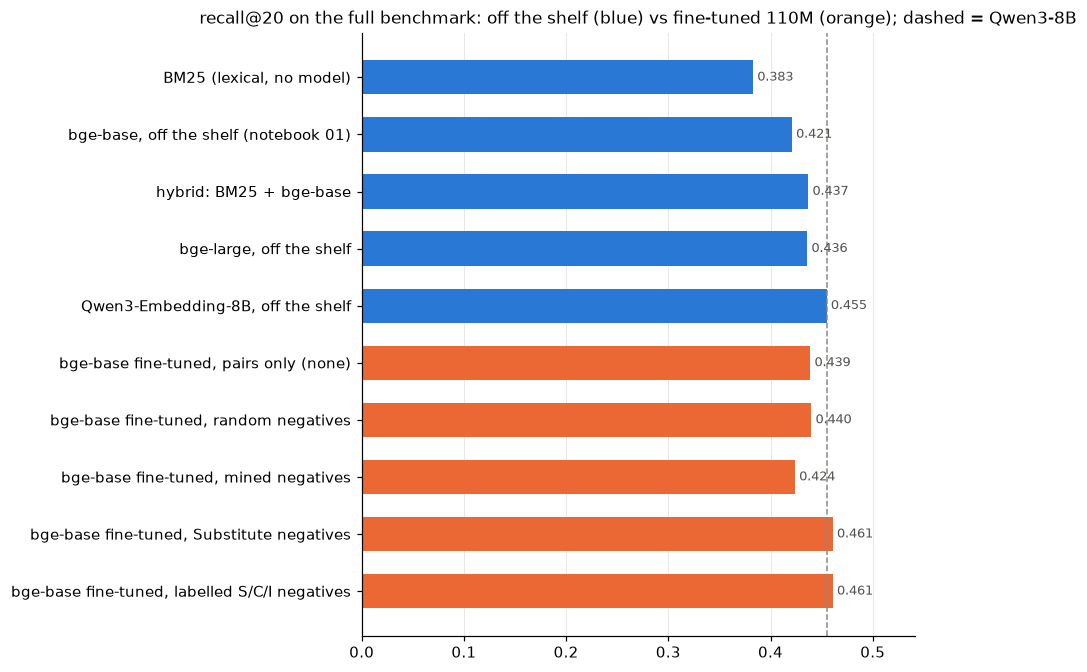

In [6]:
d = results.drop(index="bge-base, off the shelf (re-run before training)")
fig, ax = plt.subplots(figsize=(8.5, 0.5 * len(d) + 1.2))
y = np.arange(len(d))
colors = [ORANGE if "fine-tuned" in s else BLUE for s in d.index]
ax.barh(y, d["recall@20"], height=0.6, color=colors)
for yy, v in zip(y, d["recall@20"]):
    ax.text(v + 0.004, yy, f"{v:.3f}", va="center", fontsize=8.5, color="#52514e")
ax.axvline(d.loc["Qwen3-Embedding-8B, off the shelf", "recall@20"], color=GREY, linewidth=1, linestyle="--")
ax.set(yticks=y, yticklabels=d.index, xlim=(0, d["recall@20"].max() + 0.08), title="recall@20 on the full benchmark: off the shelf (blue) vs fine-tuned 110M (orange); dashed = Qwen3-8B")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

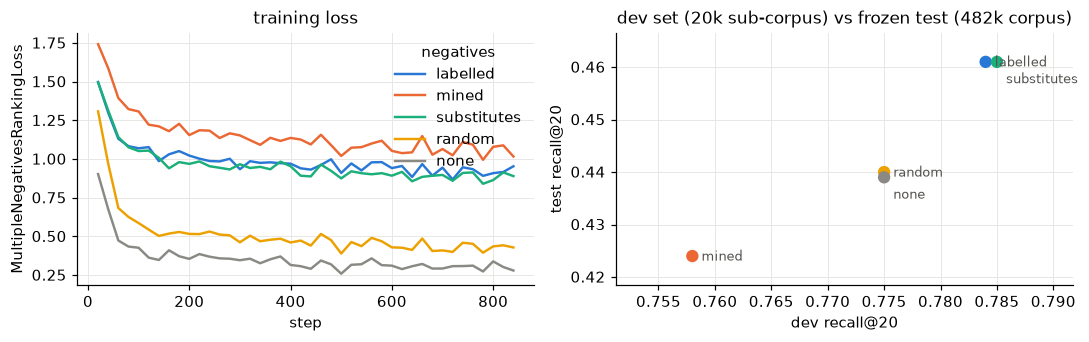

,dev recall@20,test recall@20,training (s),rows,random fallback rows
run,,,,,
labelled,0.784,0.461,488.9,54880,433
mined,0.758,0.424,501.9,54880,0
substitutes,0.785,0.461,484.8,54880,8535
random,0.775,0.440,483.5,54880,54880
none,0.775,0.439,290.1,54880,0


In [7]:
# Training curves: loss per logging step, and the dev-set recall@20 at the end of the epoch, per run.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
palette = {"embed-v1-labelled": BLUE, "embed-v1-mined": ORANGE, "embed-v1-substitutes": AQUA, "embed-v1-random": YELLOW, "embed-v1-none": GREY}
dev_rows = []
for name, rep in reports.items():
    hist = pd.DataFrame(rep["log_history"])
    tr = hist.dropna(subset=["loss"])
    axes[0].plot(tr["step"], tr["loss"], color=palette[name], linewidth=1.6, label=name.replace("embed-v1-", ""))
    ev = hist.dropna(subset=["eval_dev_cosine_recall@20"])
    dev_rows.append({"run": name.replace("embed-v1-", ""), "dev recall@20": round(float(ev["eval_dev_cosine_recall@20"].iloc[-1]), 3),
                     "test recall@20": round(rep["results"]["after"]["metrics"]["recall@20"], 3),
                     "training (s)": rep["metrics"]["wall_seconds"], "rows": rep["training_data"]["rows"], "random fallback rows": rep["training_data"]["random_fallback_rows"]})
axes[0].set(title="training loss", xlabel="step", ylabel="MultipleNegativesRankingLoss"); axes[0].legend(frameon=False, title="negatives")
dev = pd.DataFrame(dev_rows).set_index("run")
axes[1].scatter(dev["dev recall@20"], dev["test recall@20"], color=[palette["embed-v1-" + r] for r in dev.index], s=50, zorder=3)
placed = []
for r, (x_, y_) in dev[["dev recall@20", "test recall@20"]].sort_values("test recall@20", ascending=False).iterrows():
    n = sum(abs(x_ - px) < 0.006 and abs(y_ - py) < 0.005 for px, py in placed); placed.append((x_, y_))   # stack labels of near-coincident points
    axes[1].annotate(r, (x_, y_), textcoords="offset points", xytext=(6, -3 - 11 * n), fontsize=8.5, color="#52514e")
axes[1].margins(x=0.25, y=0.15)
axes[1].set(title="dev set (20k sub-corpus) vs frozen test (482k corpus)", xlabel="dev recall@20", ylabel="test recall@20")
plt.tight_layout(); plt.show()
dev

## 7. Hybrid search with the fine-tuned model

Notebook 01 found hybrid fusion worth 0.016 recall@20 over the base model alone. Does it still help when the dense
model has learned the domain? Same Reciprocal Rank Fusion of BM25 with the best fine-tuned run's rankings, on CPU.

In [8]:
BEST = results.loc[[s for s in results.index if "fine-tuned" in s], "recall@20"].idxmax()
best_run = {"bge-base fine-tuned, pairs only (none)": "embed-v1-none", "bge-base fine-tuned, random negatives": "embed-v1-random",
            "bge-base fine-tuned, mined negatives": "embed-v1-mined", "bge-base fine-tuned, Substitute negatives": "embed-v1-substitutes",
            "bge-base fine-tuned, labelled S/C/I negatives": "embed-v1-labelled"}[BEST]
print(f"best fine-tuned run: {best_run} ({BEST}: recall@20 {results.loc[BEST, 'recall@20']:.3f})")
with modal_esci.app.run():
    hyb = modal_once(f"{best_run}-hybrid", lambda: modal_esci.bm25_and_hybrid.remote(
        f"{best_run}-hybrid", LOCALE, VERSION, [f"{best_run}/rankings/after.parquet"], 0, 0, 42))
hybrid_ft = next(v for k, v in hyb["results"].items() if k.startswith("hybrid"))
HYB = "hybrid: BM25 + bge-base fine-tuned (best run)"
results.loc[HYB] = pd.Series({k: v for k, v in row(HYB, hybrid_ft, None).items() if k != "system"})
results.loc[["hybrid: BM25 + bge-base", BEST, HYB, "Qwen3-Embedding-8B, off the shelf"]]

best fine-tuned run: embed-v1-substitutes (bge-base fine-tuned, Substitute negatives: recall@20 0.461)


embed-v1-substitutes-hybrid: using the saved report at outputs/embed-v1-substitutes-hybrid/report.json


,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20
system,,,,,,,
hybrid: BM25 + bge-base,NaN,0.331,0.437,0.570,0.803,0.525,0.385
"bge-base fine-tuned, Substitute negatives",109.5,0.356,0.461,0.587,0.815,0.549,0.410
hybrid: BM25 + bge-base fine-tuned (best run),NaN,0.353,0.464,0.600,0.825,0.550,0.410
"Qwen3-Embedding-8B, off the shelf",7567.3,0.341,0.455,0.595,0.817,0.532,0.401


## 8. Error analysis: what the fine-tuned model learned, and from whom it still loses

In [9]:
pq = {
    "base": pd.read_parquet(OUT / "baselines-us-small" / "rankings" / "BAAI__bge-base-en-v1.5.per_query.parquet").set_index("query_id")["recall@20"],
    "tuned": pd.read_parquet(OUT / best_run / "rankings" / "after.per_query.parquet").set_index("query_id")["recall@20"],
    "qwen8b": pd.read_parquet(OUT / "compare-qwen" / "rankings" / "Qwen__Qwen3-Embedding-8B.per_query.parquet").set_index("query_id")["recall@20"],
    "bm25": pd.read_parquet(OUT / "baselines-us-small-bm25" / "rankings" / "bm25.per_query.parquet").set_index("query_id")["recall@20"],
}
pq = pd.DataFrame(pq)
pq["query"] = esci.data.queries_of(data["test"]).set_index("query_id")["query"]
pq["n_exact"] = data["test"][data["test"].esci_label == "E"].groupby("query_id").size()

d_base = pq.tuned - pq.base
print(f"fine-tuned vs base (recall@20 per query): better on {(d_base > 0).mean():.1%}, worse on {(d_base < 0).mean():.1%}, same on {(d_base == 0).mean():.1%}")
d_q = pq.tuned - pq.qwen8b
print(f"fine-tuned vs Qwen3-8B:                   better on {(d_q > 0).mean():.1%}, worse on {(d_q < 0).mean():.1%}, same on {(d_q == 0).mean():.1%}")
print(f"queries with no Exact in the top 20: base {(pq.base == 0).mean():.1%} → fine-tuned {(pq.tuned == 0).mean():.1%} (Qwen3-8B {(pq.qwen8b == 0).mean():.1%}, BM25 {(pq.bm25 == 0).mean():.1%})")

pd.set_option("display.max_colwidth", 60)
print("\nbiggest gains from fine-tuning:"); display(pq.loc[d_base.nlargest(8).index, ["query", "n_exact", "base", "tuned", "qwen8b", "bm25"]].round(2))
print("biggest losses from fine-tuning:"); display(pq.loc[d_base.nsmallest(8).index, ["query", "n_exact", "base", "tuned", "qwen8b", "bm25"]].round(2))
print("where Qwen3-8B still beats the fine-tuned model by the most:"); pq.loc[d_q.nsmallest(8).index, ["query", "n_exact", "base", "tuned", "qwen8b", "bm25"]].round(2)

fine-tuned vs base (recall@20 per query): better on 32.8%, worse on 16.6%, same on 50.6%
fine-tuned vs Qwen3-8B:                   better on 30.8%, worse on 28.0%, same on 41.2%
queries with no Exact in the top 20: base 20.5% → fine-tuned 18.5% (Qwen3-8B 18.3%, BM25 25.2%)

biggest gains from fine-tuning:


,query,n_exact,base,tuned,qwen8b,bm25
query_id,,,,,,
67,$10 credit not given on purchase on prime day,1,0.0,1.0,0.00,0.00
351,.5 inch suction cups without hooks,1,0.0,1.0,1.00,1.00
1118,1/4 plastic ball valve,3,0.0,1.0,0.67,0.67
1648,10x3 cheesecake boxes without windows,1,0.0,1.0,1.00,0.00
3771,36 world's softest bear,1,0.0,1.0,1.00,1.00
4658,50 ton porta power,1,0.0,1.0,1.00,0.00
4860,6 gallon water dispenser,2,0.0,1.0,0.50,0.50
5420,8x24 canvas,3,0.0,1.0,0.67,0.67


biggest losses from fine-tuning:


,query,n_exact,base,tuned,qwen8b,bm25
query_id,,,,,,
4142,"4"" non marking caster wheel",1,1.0,0.0,0.0,0.0
5295,8 slotted pot,2,1.0,0.0,0.0,0.5
12079,baby move cozy dream wedge,1,1.0,0.0,1.0,0.0
13849,batman dvd,1,1.0,0.0,0.0,1.0
14242,beamtech h11 led headlight bulb,5,1.0,0.0,0.8,1.0
20180,bt-705,1,1.0,0.0,0.0,0.0
26397,circuit joy machine,1,1.0,0.0,1.0,1.0
27039,cloth wipes container airtight,1,1.0,0.0,1.0,1.0


where Qwen3-8B still beats the fine-tuned model by the most:


,query,n_exact,base,tuned,qwen8b,bm25
query_id,,,,,,
2579,2 iron golf club,1,0.0,0.0,1.0,0.0
6565,add 12v power truck bed,2,0.0,0.0,1.0,0.5
7879,alexa bedframe,1,0.0,0.0,1.0,0.0
8942,an appeal to heaven flag,1,0.0,0.0,1.0,0.0
9806,apple tv+ app for fire stick,1,0.0,0.0,1.0,0.0
10438,arrma 6s,2,0.5,0.0,1.0,0.5
11275,auto park sensor benzel,1,0.0,0.0,1.0,1.0
11611,b'extended baton',1,0.0,0.0,1.0,0.0


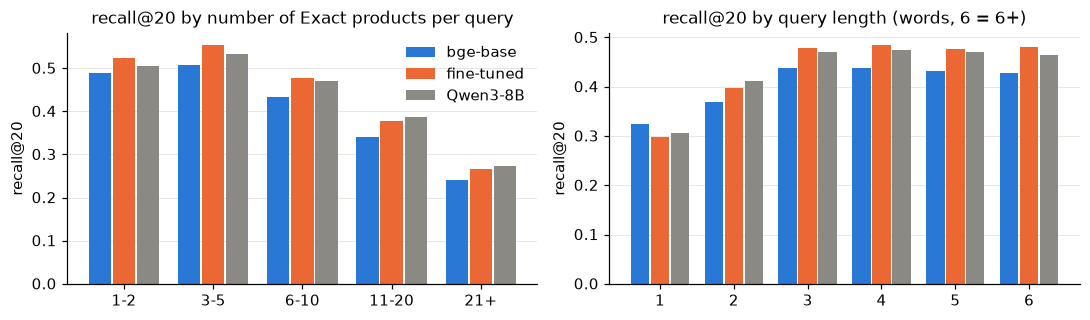

,queries,base,tuned,qwen8b
exact bucket,,,,
1-2,1271,0.488,0.523,0.505
3-5,2039,0.506,0.554,0.534
6-10,2810,0.433,0.477,0.471
11-20,2163,0.341,0.377,0.387
21+,672,0.240,0.267,0.274


In [10]:
# Does the gain depend on how many Exact products a query has, or on query length?
pq["exact bucket"] = pd.cut(pq.n_exact, [0, 2, 5, 10, 20, 100], labels=["1-2", "3-5", "6-10", "11-20", "21+"])
pq["words"] = pq["query"].str.split().str.len().clip(upper=6)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, title in ((axes[0], "exact bucket", "by number of Exact products per query"), (axes[1], "words", "by query length (words, 6 = 6+)")):
    g = pq.groupby(col, observed=True)[["base", "tuned", "qwen8b"]].mean()
    x = np.arange(len(g))
    for i, (c, color) in enumerate(zip(["base", "tuned", "qwen8b"], (BLUE, ORANGE, GREY))):
        ax.bar(x + (i - 1) * 0.27, g[c], width=0.25, color=color, label={"base": "bge-base", "tuned": "fine-tuned", "qwen8b": "Qwen3-8B"}[c])
    ax.set(xticks=x, xticklabels=[str(i) for i in g.index], title=f"recall@20 {title}", ylabel="recall@20"); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
pq.groupby("exact bucket", observed=True).agg(queries=("base", "size"), base=("base", "mean"), tuned=("tuned", "mean"), qwen8b=("qwen8b", "mean")).round(3)

## 9. How sure are we? Bootstrap intervals and extra seeds

Two sources of noise sit behind every number above, and the two checks below measure them separately. Neither
touches the official test split, so every number stays comparable with published ESCI results.

**Which queries ended up in the test set.** The 8,955 test queries are one sample of all shopping queries. A
*paired bootstrap* redraws them with replacement 2,000 times, averages each system's saved per-query scores on
each redraw (no model is re-run), and reads off the spread. "Paired" means every system is scored on the same
redraw, so a draw full of hard queries lowers all systems together and only genuine disagreements move the
difference. The share of redraws in which system A is ahead of system B is the number to quote.

**Which random choices the training run made.** The seed decides which 3 Exact products each query keeps,
which negative each row gets, the batch order, and dropout. Two more labelled runs with seeds 43 and 44, same
data and settings, scored on the same frozen test set, show how much the result moves with the dice.

In [11]:
boot = esci.bootstrap.run_all(n=2000, seed=0)
(OUT / "bootstrap.json").write_text(json.dumps(boot, indent=2))
t = boot["tables"]["stage1_recall@20"]
print(f"recall@20 on {t['queries']:,} test queries, {boot['resamples']} paired bootstrap resamples: mean and 95% interval")
display(pd.DataFrame(t["systems"]).set_index("system"))
print("differences a − b: observed, 95% interval, and the share of resamples with a ahead")
pd.DataFrame(t["differences"]).set_index("a")

recall@20 on 8,955 test queries, 2000 paired bootstrap resamples: mean and 95% interval


,mean,ci_low,ci_high
system,,,
BM25,0.3829,0.3757,0.3900
"bge-base, off the shelf",0.4208,0.4134,0.4280
hybrid: BM25 + bge-base,0.4373,0.4300,0.4443
"bge-large, off the shelf",0.4361,0.4287,0.4431
Qwen3-Embedding-0.6B,0.3763,0.3693,0.3833
Qwen3-Embedding-8B,0.4551,0.4476,0.4623
"fine-tuned, pairs only",0.4389,0.4318,0.4462
"fine-tuned, random negatives",0.4397,0.4324,0.4469
"fine-tuned, mined negatives",0.4237,0.4163,0.4307


differences a − b: observed, 95% interval, and the share of resamples with a ahead


,b,diff,ci_low,ci_high,share_a_ahead
a,,,,,
"fine-tuned, labelled negatives",Qwen3-Embedding-8B,0.0058,0.0007,0.0111,0.988
hybrid: BM25 + fine-tuned,Qwen3-Embedding-8B,0.0083,0.0027,0.0139,0.998
"fine-tuned, labelled negatives","bge-base, off the shelf",0.0402,0.0362,0.0443,1.000
"fine-tuned, labelled negatives",hybrid: BM25 + bge-base,0.0237,0.0190,0.0283,1.000
"fine-tuned, labelled negatives","bge-large, off the shelf",0.0249,0.0206,0.0294,1.000
"fine-tuned, labelled negatives","fine-tuned, random negatives",0.0213,0.0184,0.0243,1.000
"fine-tuned, labelled negatives","fine-tuned, pairs only",0.0221,0.0192,0.0249,1.000
"fine-tuned, labelled negatives","fine-tuned, mined negatives",0.0372,0.0340,0.0405,1.000
"fine-tuned, labelled negatives","fine-tuned, Substitute negatives",-0.0003,-0.0026,0.0017,0.381


In [12]:
# Same for recall@10, where the fine-tuned model's lead over the 8B model is larger.
t10 = boot["tables"]["stage1_recall@10"]
d10 = pd.DataFrame(t10["differences"]).set_index("a")
d10[d10.index == "fine-tuned, labelled negatives"]

,b,diff,ci_low,ci_high,share_a_ahead
a,,,,,
"fine-tuned, labelled negatives",Qwen3-Embedding-8B,0.0154,0.0105,0.0204,1.000
"fine-tuned, labelled negatives","bge-base, off the shelf",0.0358,0.0317,0.0397,1.000
"fine-tuned, labelled negatives",hybrid: BM25 + bge-base,0.0247,0.0203,0.0293,1.000
"fine-tuned, labelled negatives","bge-large, off the shelf",0.0241,0.0197,0.0282,1.000
"fine-tuned, labelled negatives","fine-tuned, random negatives",0.0206,0.0178,0.0233,1.000
"fine-tuned, labelled negatives","fine-tuned, pairs only",0.0228,0.0198,0.0257,1.000
"fine-tuned, labelled negatives","fine-tuned, mined negatives",0.0331,0.0299,0.0361,1.000
"fine-tuned, labelled negatives","fine-tuned, Substitute negatives",-0.0004,-0.0024,0.0018,0.365


In [13]:
# Two more seeds of the labelled configuration (skip-before: the base model's row is already measured).
SEEDS = {"embed-v1-labelled": 42, "embed-v1-labelled-seed43": 43, "embed-v1-labelled-seed44": 44}
t0 = time.time()
with modal_esci.app.run():
    jobs = {name: modal_esci.train_and_evaluate.spawn(name, MODEL_ID, LOCALE, VERSION, 1, 2e-5, 64, "labelled", 3, [], -1, 256, 0, 0, 0, seed, True)
            for name, seed in SEEDS.items() if not (OUT / name / "report.json").exists()}
    seed_reports = {name: modal_once(name, lambda name=name: jobs[name].get()) for name in SEEDS}
print(f"done in {(time.time() - t0) / 60:.1f} min\n")
seeds = pd.DataFrame([{"run": name, "seed": SEEDS[name], **{k: round(r["results"]["after"]["metrics"][k], 4) for k in ("recall@10", "recall@20", "recall@50", "hit@20", "ndcg@20")},
                       "training (s)": r["metrics"]["wall_seconds"]} for name, r in seed_reports.items()]).set_index("run")
display(seeds)
spread = seeds[["recall@10", "recall@20", "recall@50"]].agg(["mean", "std", "min", "max"]).round(4)
print("across the three seeds:"); display(spread)
q8 = results.loc["Qwen3-Embedding-8B, off the shelf", "recall@20"]
print(f"Qwen3-Embedding-8B recall@20 = {q8:.3f}; seeds ahead of it: {(seeds['recall@20'] > q8).sum()} of {len(seeds)}; "
      f"lowest seed − Qwen3-8B = {seeds['recall@20'].min() - q8:+.4f}")

embed-v1-labelled: using the saved report at outputs/embed-v1-labelled/report.json
embed-v1-labelled-seed43: using the saved report at outputs/embed-v1-labelled-seed43/report.json
embed-v1-labelled-seed44: using the saved report at outputs/embed-v1-labelled-seed44/report.json
done in 0.0 min



,seed,recall@10,recall@20,recall@50,hit@20,ndcg@20,training (s)
run,,,,,,,
embed-v1-labelled,42,0.3561,0.4610,0.5851,0.8101,0.4109,488.9
embed-v1-labelled-seed43,43,0.3540,0.4597,0.5845,0.8114,0.4089,486.8
embed-v1-labelled-seed44,44,0.3539,0.4580,0.5843,0.8119,0.4083,490.2


across the three seeds:


,recall@10,recall@20,recall@50
mean,0.3547,0.4596,0.5846
std,0.0012,0.0015,0.0004
min,0.3539,0.4580,0.5843
max,0.3561,0.4610,0.5851


Qwen3-Embedding-8B recall@20 = 0.455; seeds ahead of it: 3 of 3; lowest seed − Qwen3-8B = +0.0030


## 10. Serving the result

The fine-tuned model is a 440 MB `sentence-transformers` folder in the Modal Volume `esci-runs/<run>/model`
(`download_run(name, with_model=True)` fetches it). Serving it is the same as serving the base model: encode the
catalogue once (6 minutes on an A10G, or on CPU overnight), store 768-float vectors, encode each query at request
time with the bge prefix. Against the 8B alternative: a 768-float vector instead of 4,096 (5.3× less vector storage), a model
that fits on a CPU box, and a catalogue re-encode that costs minutes rather than hours whenever the model changes.

## 11. What comes next

- **The reranker.** A cross-encoder trained on the same (query, Exact, negative) rows, applied to the top 20 of
  the best stage-1 system, scored on nDCG and MRR at small cutoffs. That is where the position metrics belong, and
  where the 28% of queries on which fusion hurt should be recovered.
- **Epochs and batch size.** One epoch was a deliberate first step; the dev curve says whether a second one pays.
  A bigger batch is a stronger contrastive signal and the A10G has room at 256 tokens.
- **Passages with the description**, Spanish and Japanese with a multilingual model, the large version.

## 12. Gotchas

- **The same query twice in a batch is a false negative.** With several Exact products per query, use the
  `NO_DUPLICATES` sampler or cap one row per query per batch.
- **Mined negatives can be right answers.** With about 20 judged products per query, the base model's top-30
  contains unjudged products, some of them Exact. The labelled negatives do not have that problem; the comparison
  in §6 is the measurement of what it costs.
- **Dev and test disagree in level, not in order.** The dev set searches a 20k sub-corpus, so its recall is far
  higher than the test set's; use it to compare runs, never to quote a number.
- **Re-encode after every model change.** Any fine-tune invalidates every stored product vector.